# Metrical BDI Analysis: *Carmen in libros regum*

This notebook performs authorship verification on metrical patterns using the BDI (Bootstrap Distance Imposters) algorithm from the [`bdi`](https://github.com/bnagy/bdi) package.

**Pipeline:**
1. Load metrical pattern data from CSV
2. Load the scaler and author encoder fitted on known-author data
3. Run BDI verification with `minmax` metric (no feature selection)
4. Convert BDI match strengths to corpus-specific calibrated probabilities
5. Compare feature selection variants


In [3]:
import sys
from pathlib import Path
import joblib

sys.path.insert(0, "/Users/ben/code/bdi")

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import logging

from sklearn.preprocessing import StandardScaler, LabelEncoder

from bdi import BDIVerifier

logging.basicConfig(level="INFO")
logger = logging.getLogger("bdi")

import mpl_fontkit as fk

fk.install("Roboto Condensed")

Font name: `Roboto Condensed`


## Loading the data

In [5]:
def find_metrical_root():
    current = Path.cwd().resolve()

    for folder in [current, *current.parents]:
        required = [
            folder / "output.csv",
            folder / "metrical_scaler.pkl",
            folder / "metrical_label_encoder.pkl",
            folder / "metrical_bdi_calibration_model.pkl",
        ]
        if all(path.exists() for path in required):
            return folder

    raise FileNotFoundError(
        "Could not find the Metrical analysis root containing output.csv "
        "and the calibration files."
    )


BASE_DIR = find_metrical_root()

raw_df = pd.read_csv(BASE_DIR / "output.csv", encoding="utf-8")

print(f"Metrical analysis root: {BASE_DIR}")
print(f"Loaded {raw_df.shape[0]} rows, {raw_df.shape[1]} columns")
print(f"Authors/codes: {raw_df['Author'].nunique()} unique")
raw_df.head()

Metrical analysis root: /Users/martinapaccara/Documents/Documenti/Università/DOTTORATO/Lavoro/Digitale/Stilometria/elegiac_couplets/Metrical analysis
Loaded 442 rows, 46 columns
Authors/codes: 29 unique


,Author,Work,Poem,H1SP,H2SP,H3SP,H4SP,H1CF,H2CF,H3CF,...,P4SC,P1WC,P2WC,P3WC,P4WC,ELC,RS,LEO,LEN,PFSD
0,AE,bhc,bhc - 1,0.47,0.61,0.64,0.67,0.15,0.70,0.94,...,0.04,0.15,0.13,0.27,0.95,0.000,4.259122,0.954742,200,0.171447
1,AE,bhc,bhc - 2,0.53,0.63,0.70,0.78,0.22,0.76,0.93,...,0.01,0.14,0.20,0.29,0.98,0.000,4.291656,0.704966,200,0.100000
2,AE,bhc,bhc - 3,0.55,0.56,0.60,0.73,0.19,0.77,0.90,...,0.01,0.13,0.11,0.18,0.95,0.000,4.036385,0.795974,200,0.488659
3,ASt,troilus,troilus - 1,0.44,0.56,0.65,0.61,0.36,0.81,0.87,...,0.01,0.09,0.12,0.26,0.98,0.015,4.629291,1.256739,200,0.222702
4,ASt,troilus,troilus - 2,0.36,0.48,0.56,0.52,0.23,0.64,0.86,...,0.02,0.15,0.07,0.18,0.98,0.005,4.753640,1.014985,200,0.000000


## Factorizing

The BDI code needs numeric labels. We use `LabelEncoder` to convert author names to integers.

In [7]:
print(raw_df["Author"].unique())

<ArrowStringArray>
[ 'AE', 'ASt',  'BB', 'BBi',  'BI',  'BM',  'BS',  'EM',  'HA',  'HM',  'HW',
   'H',  'IS',   'M', 'NLC', 'PDE',  'PR',  'QS', 'RDV',  'RL',  'RT', 'SAC',
  'SR',  'U1',  'U2',  'U3',  'U4',  'X2',   'X']
Length: 29, dtype: str


In [8]:
label_encoder = joblib.load(
    BASE_DIR / "metrical_label_encoder.pkl"
)

print("Loaded label encoder fitted on known-author data only.")

Loaded label encoder fitted on known-author data only.


In [9]:
mapping = pd.DataFrame(
    {
        "Author": label_encoder.classes_,
        "author_label": np.arange(len(label_encoder.classes_)),
    }
)

print(mapping.to_string(index=False))
print("\nHoldout codes are not part of the encoder: X, X2")

Author  author_label
    AE             0
   ASt             1
    BB             2
   BBi             3
    BI             4
    BM             5
    BS             6
    EM             7
     H             8
    HA             9
    HM            10
    HW            11
    IS            12
     M            13
   NLC            14
   PDE            15
    PR            16
    QS            17
   RDV            18
    RL            19
    RT            20
   SAC            21
    SR            22
    U1            23
    U2            24
    U3            25
    U4            26

Holdout codes are not part of the encoder: X, X2


## Scaling

Load the scaler fitted during calibration on known-author data only, then transform the full metrical dataset. The problem texts `X_operibus` and `X2_cilr` did not contribute to scaler fitting.


In [11]:
scaler = joblib.load(
    BASE_DIR / "metrical_scaler.pkl"
)

calibration_model = joblib.load(
    BASE_DIR / "metrical_bdi_calibration_model.pkl"
)

if hasattr(scaler, "feature_names_in_"):
    numeric_cols = list(scaler.feature_names_in_)
else:
    numeric_cols = raw_df.select_dtypes(include=["number"]).columns.tolist()

df_scaled = pd.DataFrame(
    scaler.transform(raw_df[numeric_cols]),
    columns=numeric_cols,
    index=raw_df.index,
)

print(f"Scaled shape: {df_scaled.shape}")
print("Loaded corpus-specific logistic calibration model.")
df_scaled.head()

Scaled shape: (442, 43)
Loaded corpus-specific logistic calibration model.


,H1SP,H2SP,H3SP,H4SP,H1CF,H2CF,H3CF,H4CF,H1DI,H2DI,...,P4SC,P1WC,P2WC,P3WC,P4WC,ELC,RS,LEO,LEN,PFSD
0,4.517623,6.178159,8.690786,8.137651,2.317848,9.546770,16.850282,8.176137,7.554322,1.251316,...,0.279082,3.441303,2.491976,4.003875,4.190270,0.000000,6.000540,1.001771,200.0,0.505829
1,5.094340,6.380722,9.505547,9.473684,3.399511,10.365064,16.671024,7.903599,4.903683,2.252368,...,0.069770,3.211882,3.833810,4.300458,4.322595,0.000000,6.046377,0.739692,200.0,0.295036
2,5.286580,5.671753,8.147612,8.866396,2.935941,10.501447,16.133249,7.222255,4.241023,0.500526,...,0.069770,2.982462,2.108595,2.669250,4.190270,0.000000,5.686734,0.835183,200.0,1.441719
3,4.229264,5.671753,8.826580,7.408906,5.562836,11.046977,15.595474,6.268372,5.168747,3.253421,...,0.069770,2.064782,2.300286,3.855583,4.322595,0.376663,6.522059,1.318644,200.0,0.657049
4,3.460307,4.861502,7.604438,6.315789,3.554034,8.728475,15.416215,5.314489,6.361534,1.501579,...,0.139541,3.441303,1.341833,2.669250,4.322595,0.125554,6.697250,1.064982,200.0,0.000000


## Verification (no feature selection)

We hold out *Carmen in libros regum* as the problem set and verify it against all known-author candidates using the `minmax` metric.

Both attribution problems (`X_operibus` and `X2_cilr`) are excluded from the comparison corpus.


In [13]:
target_author = "X2"
target_text = "cilr"

problem_mask = (
    (raw_df["Author"].astype(str) == target_author)
    & (raw_df["Work"].astype(str) == target_text)
)

if problem_mask.sum() == 0:
    raise ValueError(
        f"No rows found for target {target_author}_{target_text}."
    )

# Both problematic texts remain complete holdouts.
comparison_mask = ~raw_df["Author"].astype(str).isin(["X", "X2"])

problem_X = df_scaled.loc[problem_mask].copy()
comparison_X = df_scaled.loc[comparison_mask].copy()

comparison_authors = raw_df.loc[
    comparison_mask, "Author"
].astype(str)

comparison_y = label_encoder.transform(comparison_authors)

print(f"Problem: {problem_X.shape} | Comparison: {comparison_X.shape}")
print(
    "Comparison authors:",
    sorted(comparison_authors.unique())
)
print(
    "Other holdout excluded from comparison:",
    sorted(
        raw_df.loc[
            raw_df["Author"].astype(str).isin(["X", "X2"])
            & ~problem_mask,
            "Author",
        ].astype(str).unique()
    )
)

Problem: (6, 43) | Comparison: (435, 43)
Comparison authors: ['AE', 'ASt', 'BB', 'BBi', 'BI', 'BM', 'BS', 'EM', 'H', 'HA', 'HM', 'HW', 'IS', 'M', 'NLC', 'PDE', 'PR', 'QS', 'RDV', 'RL', 'RT', 'SAC', 'SR', 'U1', 'U2', 'U3', 'U4']
Other holdout excluded from comparison: ['X']


In [14]:
rng = np.random.default_rng(42)

# Fit BDI verifier with minmax metric, no feature selection
bdi_mm = BDIVerifier(
    metric="minmax",
    nb_bootstrap_iter=1000,
    rnd_prop=0.35,
    random_state=rng,
)
bdi_mm.fit(comparison_X, comparison_y)

# Verify problem chunks against every candidate author
results = {}
chunk_results = {}

for int_label in sorted(set(comparison_y)):
    str_label = label_encoder.classes_[int_label]
    print(f"...... Testing against: {str_label}")

    try:
        probas = bdi_mm.predict_proba(
            problem_X,
            [int_label] * problem_X.shape[0],
        )

        probas = np.asarray(probas, dtype=float)

        calibrated = calibration_model.predict_proba(
            probas.reshape(-1, 1)
        )[:, 1]

        results[str_label] = {
            "mean": np.mean(probas),
            "std": np.std(probas),
            "calibrated_mean": np.mean(calibrated),
            "calibrated_std": np.std(calibrated),
            "calibrated_median": np.median(calibrated),
        }

        chunk_results[str_label] = pd.DataFrame(
            {
                "match_strength": probas,
                "calibrated_probability": calibrated,
            },
            index=problem_X.index,
        )

        print(
            f"    Match strength: "
            f"{np.mean(probas):.4f} ± {np.std(probas):.4f}"
        )
        print(
            f"    Calibrated P(same author): "
            f"{np.mean(calibrated):.4f} ± {np.std(calibrated):.4f}"
        )

    except Exception as e:
        print(f"    Error: {e}")

09/18/2026 07:09:20 [bdi:INFO] Fitting on 435 documents...
09/18/2026 07:09:20 [bdi:INFO] Predicting on 6 documents


...... Testing against: AE


09/18/2026 07:09:20 [bdi:INFO] Predicting on 6 documents


    Match strength: 0.0517 ± 0.0215
    Calibrated P(same author): 0.0403 ± 0.0056
...... Testing against: ASt


09/18/2026 07:09:20 [bdi:INFO] Predicting on 6 documents
09/18/2026 07:09:21 [bdi:INFO] Predicting on 6 documents


...

    Match strength: 0.6465 ± 0.1205
    Calibrated P(same author): 0.7070 ± 0.1512
...... Testing against: SAC
    Match strength: 0.1363 ± 0.0812
    Calibrated P(same author): 0.0801 ± 0.0429
...... Testing against: SR


09/18/2026 07:09:25 [bdi:INFO] Predicting on 6 documents
09/18/2026 07:09:25 [bdi:INFO] Predicting on 6 documents


    Match strength: 0.0637 ± 0.0519
    Calibrated P(same author): 0.0464 ± 0.0209
...... Testing against: U1
    Match strength: 0.0065 ± 0.0075
    Calibrated P(same author): 0.0294 ± 0.0016
...... Testing against: U2


09/18/2026 07:09:25 [bdi:INFO] Predicting on 6 documents
09/18/2026 07:09:25 [bdi:INFO] Predicting on 6 documents


    Match strength: 0.0837 ± 0.0375
    Calibrated P(same author): 0.0510 ± 0.0122
...... Testing against: U3
    Match strength: 0.0218 ± 0.0110
    Calibrated P(same author): 0.0327 ± 0.0025
...... Testing against: U4
    Match strength: 0.5977 ± 0.1494
    Calibrated P(same author): 0.6324 ± 0.2150


In [15]:
summary = pd.DataFrame(results).T
summary = summary.sort_values("calibrated_mean", ascending=False)

summary.columns = [
    "Match Strength (mean)",
    "Match Strength (std)",
    "Calibrated Probability (mean)",
    "Calibrated Probability (std)",
    "Calibrated Probability (median)",
]

summary.index.name = "Candidate"

summary = summary.round(4)

display(summary)

summary.to_csv("metrical_bdi_candidate_summary.csv")

,Match Strength (mean),Match Strength (std),Calibrated Probability (mean),Calibrated Probability (std),Calibrated Probability (median)
Candidate,,,,,
RT,0.6465,0.1205,0.7070,0.1512,0.7012
U4,0.5977,0.1494,0.6324,0.2150,0.6717
HW,0.5423,0.1017,0.5685,0.1665,0.6016
BB,0.3917,0.1220,0.3443,0.1585,0.3414
PR,0.3672,0.1200,0.3097,0.1573,0.3301
H,0.2923,0.1104,0.2120,0.1287,0.1722
BM,0.2737,0.1238,0.1998,0.1192,0.1923
RL,0.2640,0.1112,0.1851,0.1240,0.1180
NLC,0.2710,0.0646,0.1735,0.0586,0.1729


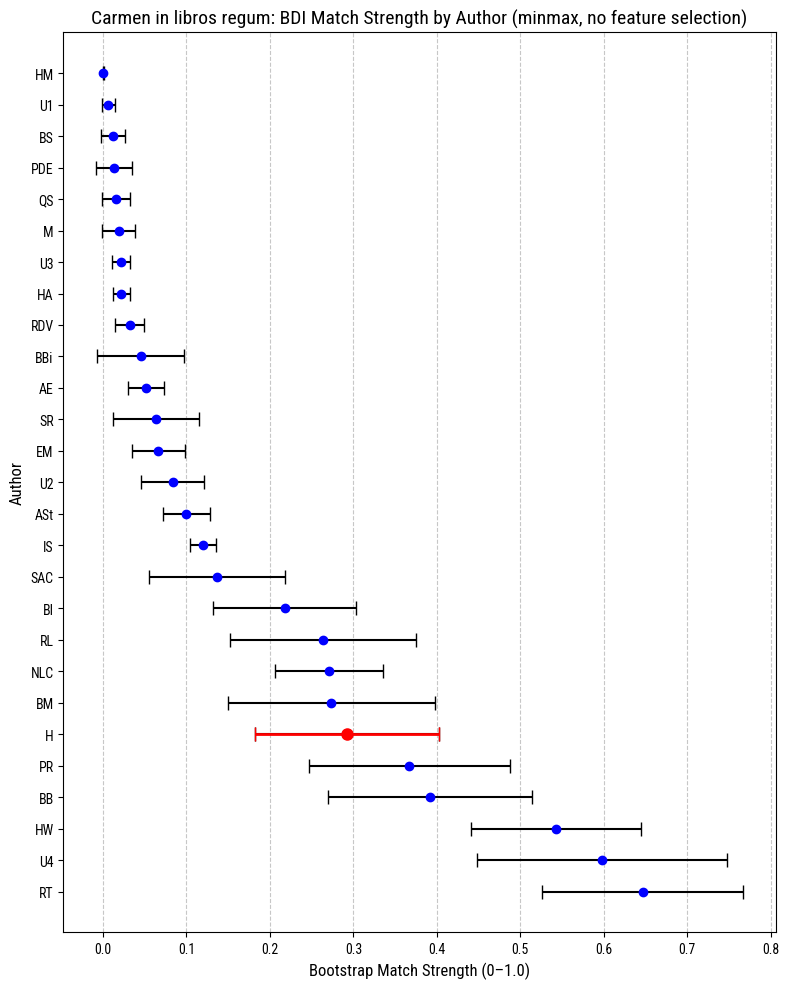

In [16]:
sorted_authors = sorted(results.items(), key=lambda x: x[1]["mean"], reverse=True)

labels_plot = [a[0] for a in sorted_authors]
means = [a[1]["mean"] for a in sorted_authors]
stds = [a[1]["std"] for a in sorted_authors]

fig, ax = plt.subplots(figsize=(8, 10))

# Tutti gli autori
ax.errorbar(
    means,
    labels_plot,
    xerr=stds,
    fmt="o",
    color="blue",
    ecolor="black",
    elinewidth=1.5,
    capsize=5,
    label="Other authors",
)

# Evidenzia H
h_idx = labels_plot.index("H")

ax.errorbar(
    means[h_idx],
    labels_plot[h_idx],
    xerr=stds[h_idx],
    fmt="o",
    color="red",
    ecolor="red",
    elinewidth=2,
    capsize=5,
    markersize=8,
    zorder=5,
    label="H",
)

ax.set_xlabel("Bootstrap Match Strength (0–1.0)", fontsize=12)
ax.set_ylabel("Author", fontsize=12)
ax.set_title(
    "Carmen in libros regum: BDI Match Strength by Author (minmax, no feature selection)",
    fontsize=14
)

ax.grid(axis="x", linestyle="--", alpha=0.7)

fig.tight_layout()
plt.savefig("carmen_in_libros_regum_forest_plot_minmax.png", dpi=300, bbox_inches="tight")
plt.show()

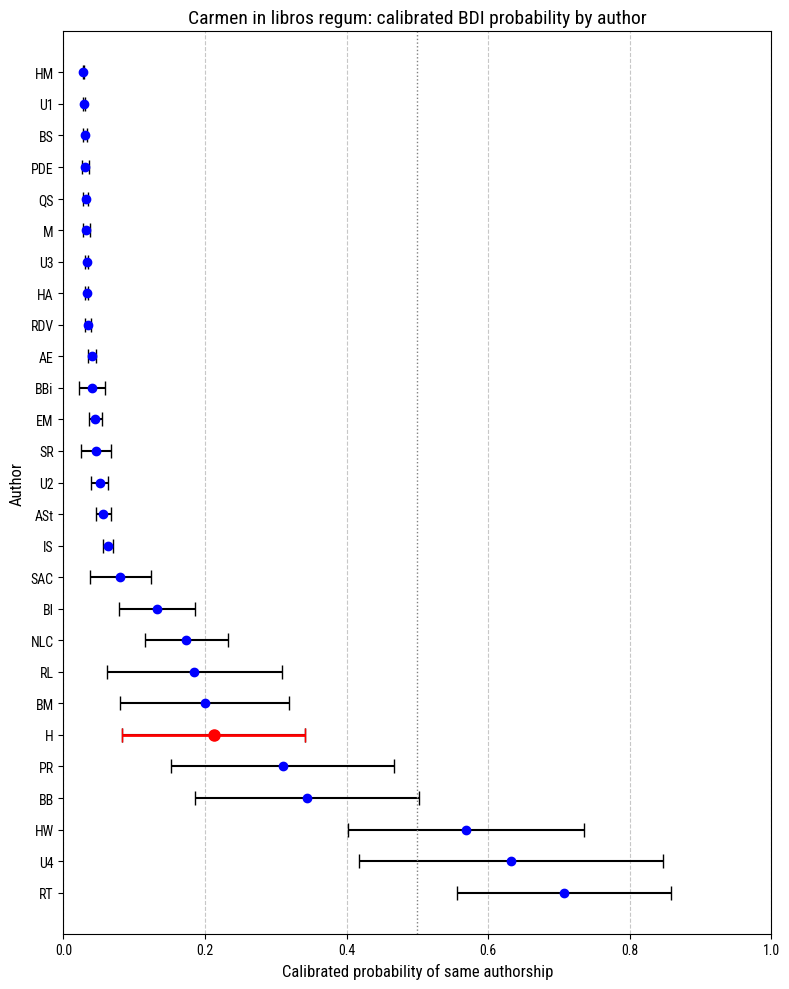

In [17]:
sorted_authors_cal = sorted(
    results.items(),
    key=lambda x: x[1]["calibrated_mean"],
    reverse=True,
)

labels_plot_cal = [a[0] for a in sorted_authors_cal]
means_cal = [a[1]["calibrated_mean"] for a in sorted_authors_cal]
stds_cal = [a[1]["calibrated_std"] for a in sorted_authors_cal]

fig, ax = plt.subplots(figsize=(8, 10))

ax.errorbar(
    means_cal,
    labels_plot_cal,
    xerr=stds_cal,
    fmt="o",
    color="blue",
    ecolor="black",
    elinewidth=1.5,
    capsize=5,
    label="Other authors",
)

h_idx_cal = labels_plot_cal.index("H")

ax.errorbar(
    means_cal[h_idx_cal],
    labels_plot_cal[h_idx_cal],
    xerr=stds_cal[h_idx_cal],
    fmt="o",
    color="red",
    ecolor="red",
    elinewidth=2,
    capsize=5,
    markersize=8,
    zorder=5,
    label="H",
)

ax.axvline(
    0.5,
    color="gray",
    linestyle=":",
    linewidth=1,
)

ax.set_xlabel("Calibrated probability of same authorship", fontsize=12)
ax.set_ylabel("Author", fontsize=12)
ax.set_title(
    "Carmen in libros regum: calibrated BDI probability by author",
    fontsize=14,
)

ax.set_xlim(0, 1)
ax.grid(axis="x", linestyle="--", alpha=0.7)

fig.tight_layout()
plt.savefig(
    "carmen_in_libros_regum_forest_plot_calibrated.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

## Ablation analysis

In [19]:
# ============================================================
# ABLATION ANALYSIS
# Carmen in libros Regum
#
# 1. Family ablation
# 2. Single-feature ablation
#
# No targeted leonine joint ablation is performed here.
#
# Interpretation of delta:
#
# Positive delta:
# removing the feature(s) lowers the match
# => the feature(s) SUPPORT similarity
#
# Negative delta:
# removing the feature(s) raises the match
# => the feature(s) WORK AGAINST similarity
# ============================================================

import pandas as pd
import numpy as np


# ============================================================
# SETTINGS
# ============================================================

# Candidates of particular interest:
#
# RT = Radulfus Tortarius
# U4 = Liber Regum
# HW = Hermannus / Ermanno of Werden
# H  = Hildebertus Cenomanensis

candidates_of_interest = ["RT", "U4", "HW", "H"]

# Same seeds used in the other ablation experiments
seeds = [11, 22, 33, 44, 55]

# All metrical features actually used by the model
all_features = list(problem_X.columns)

print("Features used in full model:")
print(all_features)
print("Number of features:", len(all_features))


# ============================================================
# CHECK CANDIDATES
# ============================================================

missing_candidates = [
    candidate
    for candidate in candidates_of_interest
    if candidate not in label_encoder.classes_
]

if missing_candidates:
    raise ValueError(
        f"Candidates not found in label_encoder: {missing_candidates}"
    )

print("\nCandidates analysed:")
print(candidates_of_interest)


# ============================================================
# FEATURE FAMILIES
#
# H = hexameter
# P = pentameter
#
# SP   = spondaic feet
# CF   = ictus / word-accent conflict
# DI   = diaeresis
# SC   = strong caesura
# WC   = weak caesura
# ELC  = mean elisions per verse
# RS   = rhyme strength
# LEO  = leonine-rhyme frequency
# PFSD = pentameter final-word length variability
# LEN  = length
# ============================================================

feature_families = {

    "Spondees": [
        f for f in all_features
        if f.endswith("SP")
    ],

    "Ictus-accent conflict": [
        f for f in all_features
        if f.endswith("CF")
    ],

    "Diaereses": [
        f for f in all_features
        if f.endswith("DI")
    ],

    "Strong caesurae": [
        f for f in all_features
        if f.endswith("SC")
    ],

    "Weak caesurae": [
        f for f in all_features
        if f.endswith("WC")
    ],

    "Elisions": [
        f for f in all_features
        if f == "ELC"
    ],

    "Rhyme strength": [
        f for f in all_features
        if f == "RS"
    ],

    "Leonine rhyme": [
        f for f in all_features
        if f == "LEO"
    ],

    "Pentameter final-word length SD": [
        f for f in all_features
        if f == "PFSD"
    ],

    "Length": [
        f for f in all_features
        if f == "LEN"
    ],
}


# Remove empty families automatically
feature_families = {
    family: features
    for family, features in feature_families.items()
    if len(features) > 0
}


print("\nFeature families:")

for family, features in feature_families.items():
    print(f"{family}: {features}")


# ============================================================
# CHECK THAT EVERY FEATURE BELONGS TO A FAMILY
# ============================================================

features_in_families = set(
    feature
    for features in feature_families.values()
    for feature in features
)

unassigned_features = [
    feature
    for feature in all_features
    if feature not in features_in_families
]

if unassigned_features:
    print(
        "\nWARNING: the following features are not assigned "
        "to any family:"
    )
    print(unassigned_features)
else:
    print("\nAll features are assigned to a family.")


# ============================================================
# HELPER:
# CONVERT CANDIDATE STRING LABEL TO ENCODED LABEL
# ============================================================

def get_encoded_label(candidate):

    matches = np.where(
        label_encoder.classes_ == candidate
    )[0]

    if len(matches) != 1:
        raise ValueError(
            f"Could not uniquely identify candidate {candidate}"
        )

    return int(matches[0])


# ============================================================
# HELPER:
# RUN BDI FOR SELECTED CANDIDATES
# ============================================================

def run_bdi_selected(features, seed=42):

    rng = np.random.default_rng(seed)

    verifier = BDIVerifier(
        metric="minmax",
        nb_bootstrap_iter=1000,
        rnd_prop=0.5,
        random_state=rng,
    )

    verifier.fit(
        comparison_X[features],
        comparison_y
    )

    results = {}

    for candidate in candidates_of_interest:

        int_label = get_encoded_label(candidate)

        scores = verifier.predict_proba(
            problem_X[features],
            [int_label] * problem_X.shape[0],
        )

        scores = np.asarray(
            scores,
            dtype=float
        )

        results[candidate] = {
            "mean": scores.mean(),
            "std_chunks": scores.std(),
            "chunks": scores.copy(),
        }

    return results


# ============================================================
# HELPER:
# AGGREGATE RESULTS ACROSS SEEDS
# ============================================================

def aggregate_ablation(df, group_columns):

    summary = (
        df
        .groupby(
            group_columns,
            as_index=False
        )
        .agg(

            baseline_mean=(
                "Baseline match",
                "mean"
            ),

            ablated_mean=(
                "Ablated match",
                "mean"
            ),

            delta_mean=(
                "Delta",
                "mean"
            ),

            delta_std=(
                "Delta",
                "std"
            ),

            delta_min=(
                "Delta",
                "min"
            ),

            delta_max=(
                "Delta",
                "max"
            ),
        )
    )

    # Stability of effect direction across seeds
    direction = (
        df
        .groupby(group_columns)
        ["Delta"]
        .agg(

            positive_fraction=lambda x: (
                x > 0
            ).mean(),

            negative_fraction=lambda x: (
                x < 0
            ).mean(),

        )
        .reset_index()
    )

    summary = summary.merge(
        direction,
        on=group_columns,
        how="left"
    )

    return summary


# ============================================================
# STORAGE
# ============================================================

family_rows = []
single_rows = []


# ============================================================
# RUN ALL ABLATION ANALYSES
# ============================================================

for seed in seeds:

    print(f"\n===== SEED {seed} =====")


    # --------------------------------------------------------
    # BASELINE
    # Full model
    # --------------------------------------------------------

    baseline = run_bdi_selected(
        all_features,
        seed=seed
    )


    # --------------------------------------------------------
    # 1. FAMILY ABLATION
    # --------------------------------------------------------

    for family_name, removed_features in feature_families.items():

        retained_features = [
            feature
            for feature in all_features
            if feature not in removed_features
        ]

        ablated = run_bdi_selected(
            retained_features,
            seed=seed
        )

        for candidate in candidates_of_interest:

            baseline_match = (
                baseline[candidate]["mean"]
            )

            ablated_match = (
                ablated[candidate]["mean"]
            )

            delta = (
                baseline_match
                - ablated_match
            )

            family_rows.append({

                "Seed": seed,

                "Candidate": candidate,

                "Family": family_name,

                "Baseline match": baseline_match,

                "Ablated match": ablated_match,

                "Delta": delta,

            })


    # --------------------------------------------------------
    # 2. SINGLE-FEATURE ABLATION
    # --------------------------------------------------------

    for removed_feature in all_features:

        retained_features = [
            feature
            for feature in all_features
            if feature != removed_feature
        ]

        ablated = run_bdi_selected(
            retained_features,
            seed=seed
        )

        for candidate in candidates_of_interest:

            baseline_match = (
                baseline[candidate]["mean"]
            )

            ablated_match = (
                ablated[candidate]["mean"]
            )

            delta = (
                baseline_match
                - ablated_match
            )

            single_rows.append({

                "Seed": seed,

                "Candidate": candidate,

                "Feature": removed_feature,

                "Baseline match": baseline_match,

                "Ablated match": ablated_match,

                "Delta": delta,

            })


# ============================================================
# CREATE DATAFRAMES
# ============================================================

family_raw = pd.DataFrame(
    family_rows
)

single_raw = pd.DataFrame(
    single_rows
)


# ============================================================
# AGGREGATE RESULTS
# ============================================================

family_summary = aggregate_ablation(
    family_raw,
    ["Candidate", "Family"]
)

single_summary = aggregate_ablation(
    single_raw,
    ["Candidate", "Feature"]
)


# ============================================================
# CANDIDATE ORDER
# ============================================================

for df in [
    family_summary,
    single_summary
]:

    df["Candidate"] = pd.Categorical(
        df["Candidate"],
        categories=candidates_of_interest,
        ordered=True
    )


# ============================================================
# TABLE 1
# FAMILY ABLATION
# ============================================================

# Use dictionary order directly.
# This avoids category-order mismatches.

family_order = list(
    feature_families.keys()
)

family_summary["Family"] = pd.Categorical(
    family_summary["Family"],
    categories=family_order,
    ordered=True
)

family_summary = (
    family_summary
    .sort_values(
        ["Candidate", "Family"]
    )
    .reset_index(drop=True)
)


family_delta_matrix = (
    family_summary
    .pivot(
        index="Family",
        columns="Candidate",
        values="delta_mean"
    )
    .reindex(family_order)
    [candidates_of_interest]
)


print("\n\n")
print("=" * 76)
print("TABLE 1 — FAMILY ABLATION")
print("=" * 76)

print(
    "\nPositive value = family supports similarity"
)

print(
    "Negative value = family works against similarity"
)

display(
    family_delta_matrix.round(4)
)


# ============================================================
# TABLE 2
# SINGLE-FEATURE ABLATION
# ============================================================

preferred_order = [

    # --------------------------------------------------------
    # Spondees
    # --------------------------------------------------------

    "H1SP", "H2SP", "H3SP", "H4SP",
    "P1SP", "P2SP",

    # --------------------------------------------------------
    # Ictus-accent conflict
    # --------------------------------------------------------

    "H1CF", "H2CF", "H3CF", "H4CF",
    "P1CF", "P2CF", "P3CF", "P4CF",

    # --------------------------------------------------------
    # Diaereses
    # --------------------------------------------------------

    "H1DI", "H2DI", "H3DI", "H4DI",
    "P1DI", "P2DI", "P3DI", "P4DI",

    # --------------------------------------------------------
    # Strong caesurae
    # --------------------------------------------------------

    "H1SC", "H2SC", "H3SC", "H4SC",
    "P1SC", "P2SC", "P3SC", "P4SC",

    # --------------------------------------------------------
    # Weak caesurae
    # --------------------------------------------------------

    "H1WC", "H2WC", "H3WC", "H4WC",
    "P1WC", "P2WC", "P3WC", "P4WC",

    # --------------------------------------------------------
    # Global features
    # --------------------------------------------------------

    "ELC",
    "RS",
    "LEO",
    "PFSD",
    "LEN",
]


# Keep only features actually present
preferred_order = [
    feature
    for feature in preferred_order
    if feature in all_features
]


# Add any unexpected feature at the end,
# so that nothing is silently omitted
remaining_features = [
    feature
    for feature in all_features
    if feature not in preferred_order
]

preferred_order += remaining_features


single_delta_matrix = (
    single_summary
    .pivot(
        index="Feature",
        columns="Candidate",
        values="delta_mean"
    )
    .reindex(preferred_order)
    [candidates_of_interest]
)


print("\n\n")
print("=" * 76)
print("TABLE 2 — SINGLE-FEATURE ABLATION")
print("=" * 76)

print(
    "\nPositive value = feature supports similarity"
)

print(
    "Negative value = feature works against similarity"
)

display(
    single_delta_matrix.round(4)
)


# ============================================================
# TABLE 3
# DETAILED SINGLE-FEATURE RESULTS BY CANDIDATE
# ============================================================

for candidate in candidates_of_interest:

    print(
        f"\n\n===== SINGLE FEATURES: {candidate} ====="
    )

    candidate_table = (
        single_summary[
            single_summary["Candidate"]
            == candidate
        ]
        .set_index("Feature")
        .reindex(preferred_order)
        .reset_index()
        [
            [
                "Feature",
                "baseline_mean",
                "ablated_mean",
                "delta_mean",
                "delta_std",
                "positive_fraction",
                "negative_fraction",
            ]
        ]
    )

    display(
        candidate_table.round(4)
    )


# ============================================================
# TABLE 4
# LARGEST SINGLE-FEATURE EFFECTS BY CANDIDATE
# ============================================================

for candidate in candidates_of_interest:

    print(
        f"\n\n===== LARGEST EFFECTS: {candidate} ====="
    )

    ranked = (
        single_summary[
            single_summary["Candidate"]
            == candidate
        ]
        .copy()
    )

    ranked["abs_delta"] = (
        ranked["delta_mean"].abs()
    )

    ranked = (
        ranked
        .sort_values(
            "abs_delta",
            ascending=False
        )
        [
            [
                "Feature",
                "baseline_mean",
                "ablated_mean",
                "delta_mean",
                "delta_std",
                "positive_fraction",
                "negative_fraction",
            ]
        ]
    )

    display(
        ranked.head(10).round(4)
    )


# ============================================================
# SAVE RESULTS
# ============================================================

family_raw.to_csv(
    "carmen_regum_family_ablation_raw.csv",
    index=False
)

family_summary.to_csv(
    "carmen_regum_family_ablation_summary.csv",
    index=False
)

family_delta_matrix.to_csv(
    "carmen_regum_family_ablation_deltas.csv"
)


single_raw.to_csv(
    "carmen_regum_single_feature_ablation_raw.csv",
    index=False
)

single_summary.to_csv(
    "carmen_regum_single_feature_ablation_summary.csv",
    index=False
)

single_delta_matrix.to_csv(
    "carmen_regum_single_feature_ablation_deltas.csv"
)


# ============================================================
# DONE
# ============================================================

print("\n")
print("=" * 76)
print("DONE")
print("=" * 76)

print(
    "\nSaved family and single-feature "
    "ablation results for Carmen in libros Regum."
)

09/18/2026 07:09:27 [bdi:INFO] Fitting on 435 documents...
09/18/2026 07:09:27 [bdi:INFO] Predicting on 6 documents


Features used in full model:
['H1SP', 'H2SP', 'H3SP', 'H4SP', 'H1CF', 'H2CF', 'H3CF', 'H4CF', 'H1DI', 'H2DI', 'H3DI', 'H4DI', 'H1SC', 'H2SC', 'H3SC', 'H4SC', 'H1WC', 'H2WC', 'H3WC', 'H4WC', 'P1SP', 'P2SP', 'P1CF', 'P2CF', 'P3CF', 'P4CF', 'P1DI', 'P2DI', 'P3DI', 'P4DI', 'P1SC', 'P2SC', 'P3SC', 'P4SC', 'P1WC', 'P2WC', 'P3WC', 'P4WC', 'ELC', 'RS', 'LEO', 'LEN', 'PFSD']
Number of features: 43

Candidates analysed:
['RT', 'U4', 'HW', 'H']

Feature families:
Spondees: ['H1SP', 'H2SP', 'H3SP', 'H4SP', 'P1SP', 'P2SP']
Ictus-accent conflict: ['H1CF', 'H2CF', 'H3CF', 'H4CF', 'P1CF', 'P2CF', 'P3CF', 'P4CF']
Diaereses: ['H1DI', 'H2DI', 'H3DI', 'H4DI', 'P1DI', 'P2DI', 'P3DI', 'P4DI']
Strong caesurae: ['H1SC', 'H2SC', 'H3SC', 'H4SC', 'P1SC', 'P2SC', 'P3SC', 'P4SC']
Weak caesurae: ['H1WC', 'H2WC', 'H3WC', 'H4WC', 'P1WC', 'P2WC', 'P3WC', 'P4WC']
Elisions: ['ELC']
Rhyme strength: ['RS']
Leonine rhyme: ['LEO']
Pentameter final-word length SD: ['PFSD']
Length: ['LEN']

All features are assigned to a fami

09/18/2026 07:09:27 [bdi:INFO] Predicting on 6 documents
09/18/2026 07:09:27 [bdi:INFO] Predicting on 6 documents
09/18/2026 07:09:28 [bdi:INFO] Predicting on 6 documents
09/18/2026 07:09:28 [bdi:INFO] Fitting on 435 documents...
09/18/2026 07:09:28 [bdi:INFO] Predicting on 6 documents
09/18/2026 07:09:28 [bdi:INFO] Predicting on 6 documents
09/18/2026 07:09:28 [bdi:INFO] Predicting on 6 documents
09/18/2026 07:09:29 [bdi:INFO] Predicting on 6 documents
09/18/2026 07:09:29 [bdi:INFO] Fitting on 435 documents...
09/18/2026 07:09:29 [bdi:INFO] Predicting on 6 documents
09/18/2026 07:09:29 [bdi:INFO] Predicting on 6 documents
09/18/2026 07:09:29 [bdi:INFO] Predicting on 6 documents
09/18/2026 07:09:29 [bdi:INFO] Predicting on 6 documents
09/18/2026 07:09:30 [bdi:INFO] Fitting on 435 documents...
09/18/2026 07:09:30 [bdi:INFO] Predicting on 6 documents
09/18/2026 07:09:30 [bdi:INFO] Predicting on 6 documents
09/18/2026 07:09:30 [bdi:INFO] Predicting on 6 documents
09/18/2026 07:09:30 [bdi:


===== SEED 22 =====


09/18/2026 07:10:20 [bdi:INFO] Predicting on 6 documents
09/18/2026 07:10:20 [bdi:INFO] Predicting on 6 documents
09/18/2026 07:10:20 [bdi:INFO] Predicting on 6 documents
09/18/2026 07:10:21 [bdi:INFO] Fitting on 435 documents...
09/18/2026 07:10:21 [bdi:INFO] Predicting on 6 documents
09/18/2026 07:10:21 [bdi:INFO] Predicting on 6 documents
09/18/2026 07:10:21 [bdi:INFO] Predicting on 6 documents
09/18/2026 07:10:21 [bdi:INFO] Predicting on 6 documents
09/18/2026 07:10:22 [bdi:INFO] Fitting on 435 documents...
09/18/2026 07:10:22 [bdi:INFO] Predicting on 6 documents
09/18/2026 07:10:22 [bdi:INFO] Predicting on 6 documents
09/18/2026 07:10:22 [bdi:INFO] Predicting on 6 documents
09/18/2026 07:10:22 [bdi:INFO] Predicting on 6 documents
09/18/2026 07:10:23 [bdi:INFO] Fitting on 435 documents...
09/18/2026 07:10:23 [bdi:INFO] Predicting on 6 documents
09/18/2026 07:10:23 [bdi:INFO] Predicting on 6 documents
09/18/2026 07:10:23 [bdi:INFO] Predicting on 6 documents
09/18/2026 07:10:23 [bdi:

...



===== LARGEST EFFECTS: HW =====


,Feature,baseline_mean,ablated_mean,delta_mean,delta_std,positive_fraction,negative_fraction
84,PFSD,0.5751,0.6674,-0.0922,0.0064,0.0,1.0
72,P2DI,0.5751,0.4840,0.0911,0.0086,1.0,0.0
83,P4WC,0.5751,0.6541,-0.0789,0.0069,0.0,1.0
80,P4CF,0.5751,0.6515,-0.0763,0.0045,0.0,1.0
82,P4SC,0.5751,0.6382,-0.0630,0.0057,0.0,1.0
78,P3SC,0.5751,0.5180,0.0572,0.0053,1.0,0.0
73,P2SC,0.5751,0.5248,0.0504,0.0065,1.0,0.0
70,P1WC,0.5751,0.6221,-0.0470,0.0037,0.0,1.0
48,H1WC,0.5751,0.6169,-0.0417,0.0033,0.0,1.0
47,H1SP,0.5751,0.6110,-0.0358,0.0077,0.0,1.0




===== LARGEST EFFECTS: H =====


,Feature,baseline_mean,ablated_mean,delta_mean,delta_std,positive_fraction,negative_fraction
8,H2SC,0.3627,0.2769,0.0858,0.0029,1.0,0.0
39,P4SC,0.3627,0.4407,-0.0780,0.0071,0.0,1.0
4,H1SP,0.3627,0.2869,0.0758,0.0073,1.0,0.0
37,P4CF,0.3627,0.4372,-0.0745,0.0057,0.0,1.0
5,H1WC,0.3627,0.2976,0.0651,0.0057,1.0,0.0
13,H3SC,0.3627,0.4272,-0.0645,0.0049,0.0,1.0
40,P4WC,0.3627,0.4218,-0.0591,0.0043,0.0,1.0
15,H3WC,0.3627,0.4144,-0.0517,0.0045,0.0,1.0
11,H3CF,0.3627,0.4062,-0.0435,0.0053,0.0,1.0
30,P2SC,0.3627,0.3211,0.0416,0.0058,1.0,0.0




DONE

Saved family and single-feature ablation results for Carmen in libros Regum.


## Interpretation

The raw BDI match strength is retained as the direct output of the verifier. Its corpus-specific interpretation is provided by the logistic calibration estimated on known-author cases in `2. evaluate_calibrate_metric.ipynb`.

`Calibrated Probability` is the logistic transformation of each segment-level BDI match strength. Values closer to 1 are more compatible with the known same-author calibration cases; values closer to 0 are more compatible with the different-author cases.

## Chunked Visualization

We can inspect the full bootstrap distance distribution per chunk using `_dist_arrays`. This shows the uncertainty in our determinations.


### Candidate: Hildebert (H)

In [22]:
label_index_H = label_encoder.transform(["H"])[0]

bdi_mm.predict_proba(
    problem_X,
    [label_index_H] * problem_X.shape[0],
)

carmen_in_libros_regum_vs_hildebert = pd.DataFrame(
    dict(zip(raw_df.loc[problem_mask].index, bdi_mm._dist_arrays))
)

carmen_in_libros_regum_vs_hildebert

09/18/2026 07:13:52 [bdi:INFO] Predicting on 6 documents


,435,436,437,438,439,440
0,-0.033194,-0.029676,-0.007767,0.008187,0.003936,-0.025734
1,-0.046637,0.002280,-0.021746,0.011678,-0.059446,-0.003668
2,-0.017896,-0.073045,-0.021247,-0.014137,-0.016564,-0.011933
3,-0.064921,0.019889,-0.029765,-0.005340,-0.106563,-0.061289
4,-0.033266,0.010231,-0.021706,-0.023040,0.004893,-0.077173
...,...,...,...,...,...,...
995,-0.059989,-0.038359,-0.001824,0.030422,-0.003626,-0.012368
996,0.002666,-0.019840,-0.018913,-0.035657,-0.008926,-0.043753
997,-0.059339,-0.019852,-0.011793,-0.006544,-0.008447,-0.049069
998,-0.003330,-0.022712,-0.012412,0.003428,-0.023723,-0.009749


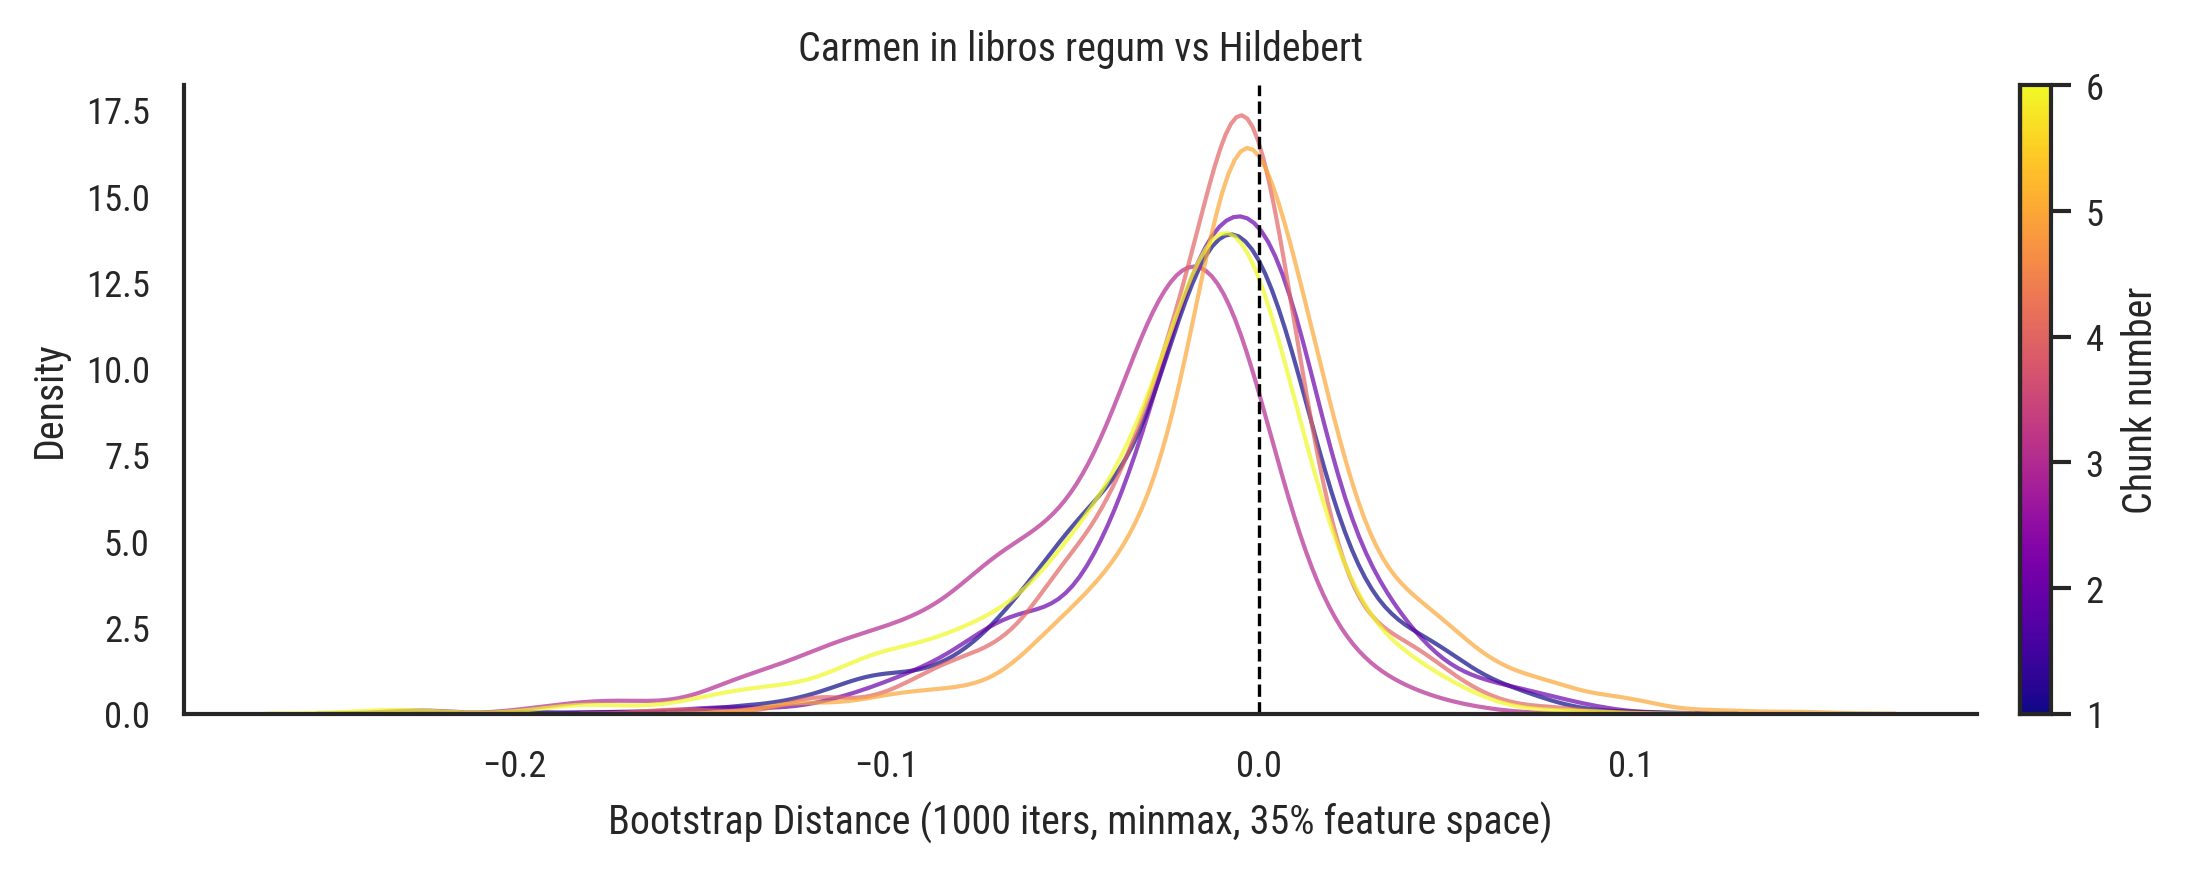

In [23]:
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import re


def plot_kde_viridis(dist_df, poem_names, title="", xlabel="", ax=None):
    """Plot KDE curves colored by chunk number using viridis plasma.

    Later chunks (higher number in poem name) get darker colors.
    """
    # Extract chunk numbers from poem 
    chunk_nums = []
    for idx in dist_df.columns:
        name = poem_names.loc[idx, "Poem"] if idx in poem_names.index else str(idx)
        m = re.search(r"(\d+)", name)
        chunk_nums.append(int(m.group(1)) if m else 0)

    chunk_nums = np.array(chunk_nums)
    n_chunks = len(chunk_nums)

    # Normalize chunk numbers to [0, 1] for colormap
    if chunk_nums.max() > chunk_nums.min():
        norm_vals = (chunk_nums - chunk_nums.min()) / (
            chunk_nums.max() - chunk_nums.min()
        )
    else:
        norm_vals = np.ones(n_chunks) * 0.5

    # Plasma: low values = bright/yellow, high values = dark/purple
    cmap = cm.plasma
    colors = [cmap(v) for v in norm_vals]

    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 3))

    for col, color in zip(dist_df.columns, colors):
        sns.kdeplot(dist_df[col], color=color, linewidth=1, alpha=0.7, ax=ax)

    ax.axvline(0, color="black", linestyle="--", linewidth=0.8)
    ax.set(xlabel=xlabel, ylabel="Density", title=title)

    # Add colorbar as legend
    sm = cm.ScalarMappable(
        cmap=cmap, norm=mcolors.Normalize(vmin=chunk_nums.min(), vmax=chunk_nums.max())
    )
    sm.set_array([])
    cbar = plt.colorbar(sm, ax=ax, pad=0.02)
    cbar.set_label("Chunk number")

    return ax


poem_names = raw_df.loc[problem_mask]

sns.set_theme(
    context="paper",
    font="Roboto Condensed",
    style="white",
    rc={"figure.figsize": (8, 3), "figure.dpi": 300},
)
fig, ax = plt.subplots(figsize=(8, 3))
plot_kde_viridis(
    carmen_in_libros_regum_vs_hildebert,
    poem_names,
    title="Carmen in libros regum vs Hildebert",
    xlabel="Bootstrap Distance (1000 iters, minmax, 35% feature space)",
    ax=ax,
)
sns.despine()
fig.tight_layout()
plt.savefig(f"cilr_vs_H.png", dpi=300, bbox_inches="tight")
plt.show()

NOTE: raw BDI match strengths are not probabilities. The calibrated probabilities reported above are obtained from the corpus-specific logistic calibration on known-author cases.

## Additional Candidates

We test several alternative candidates to compare their bootstrap distance distributions.


09/18/2026 07:13:53 [bdi:INFO] Predicting on 6 documents


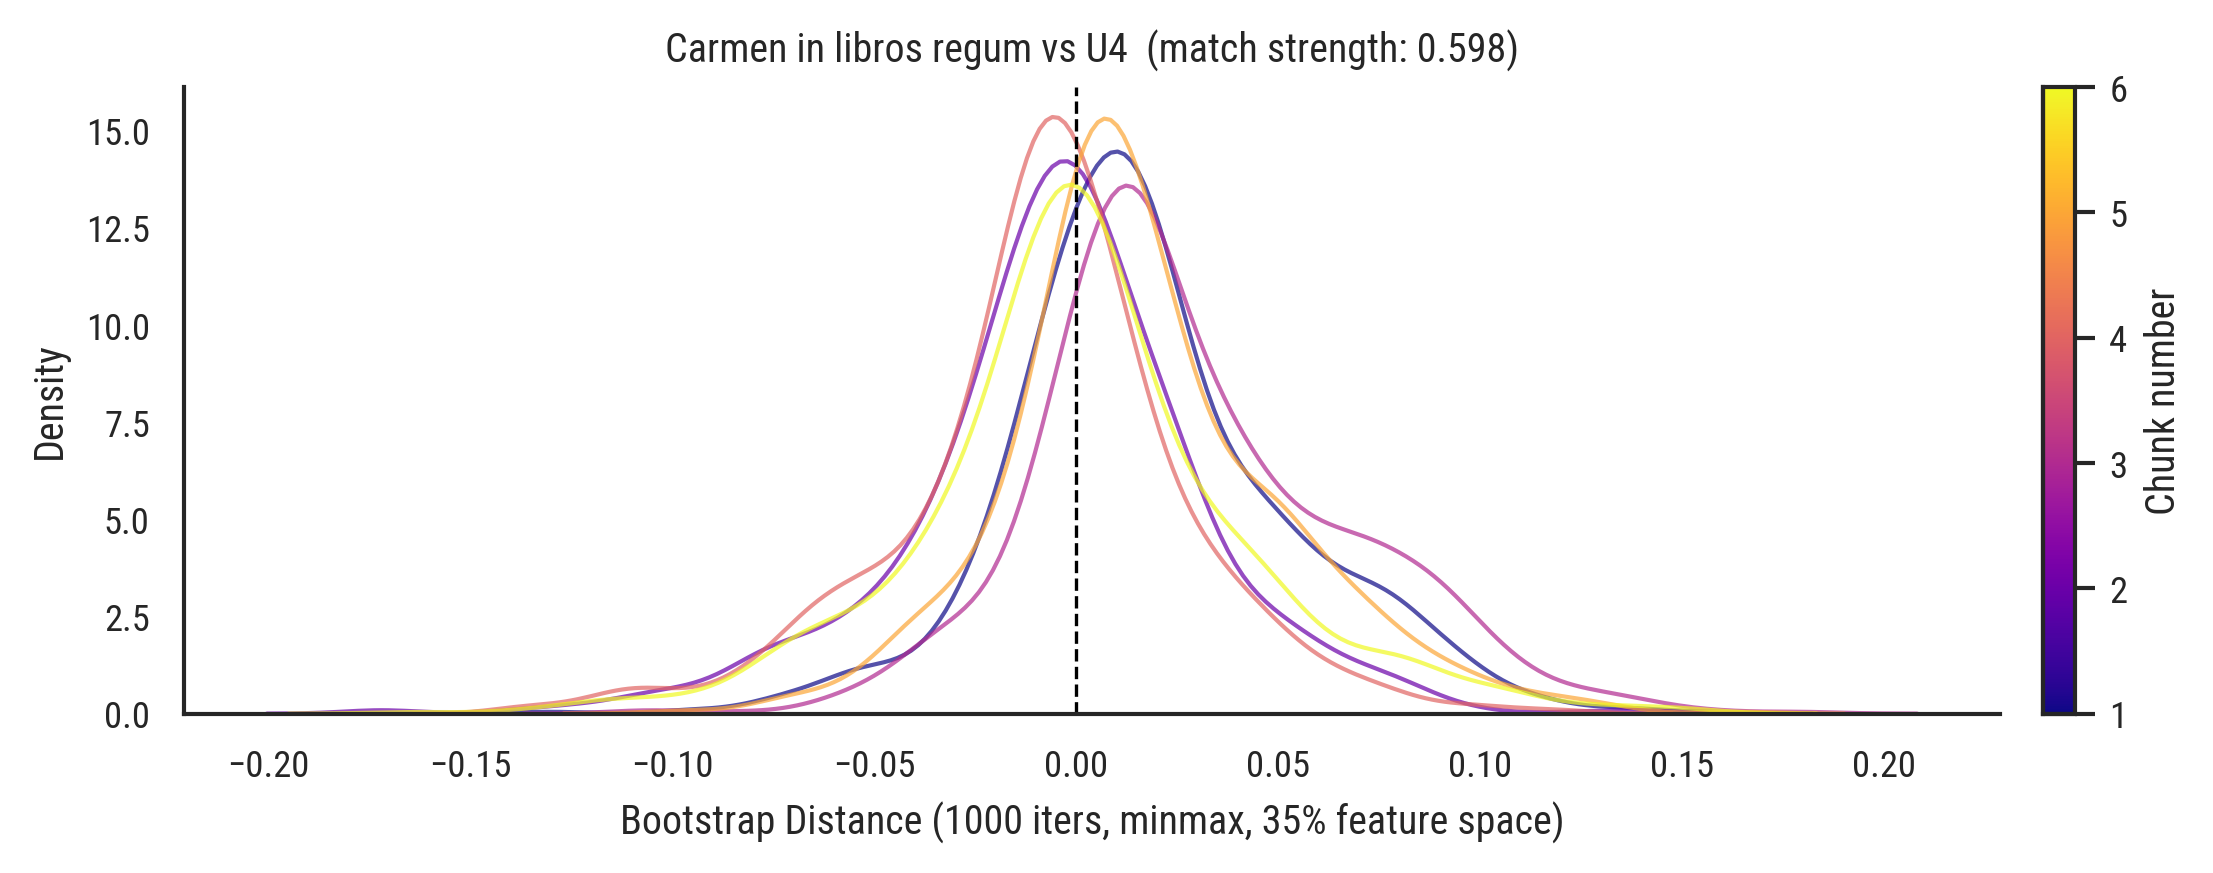

09/18/2026 07:13:53 [bdi:INFO] Predicting on 6 documents


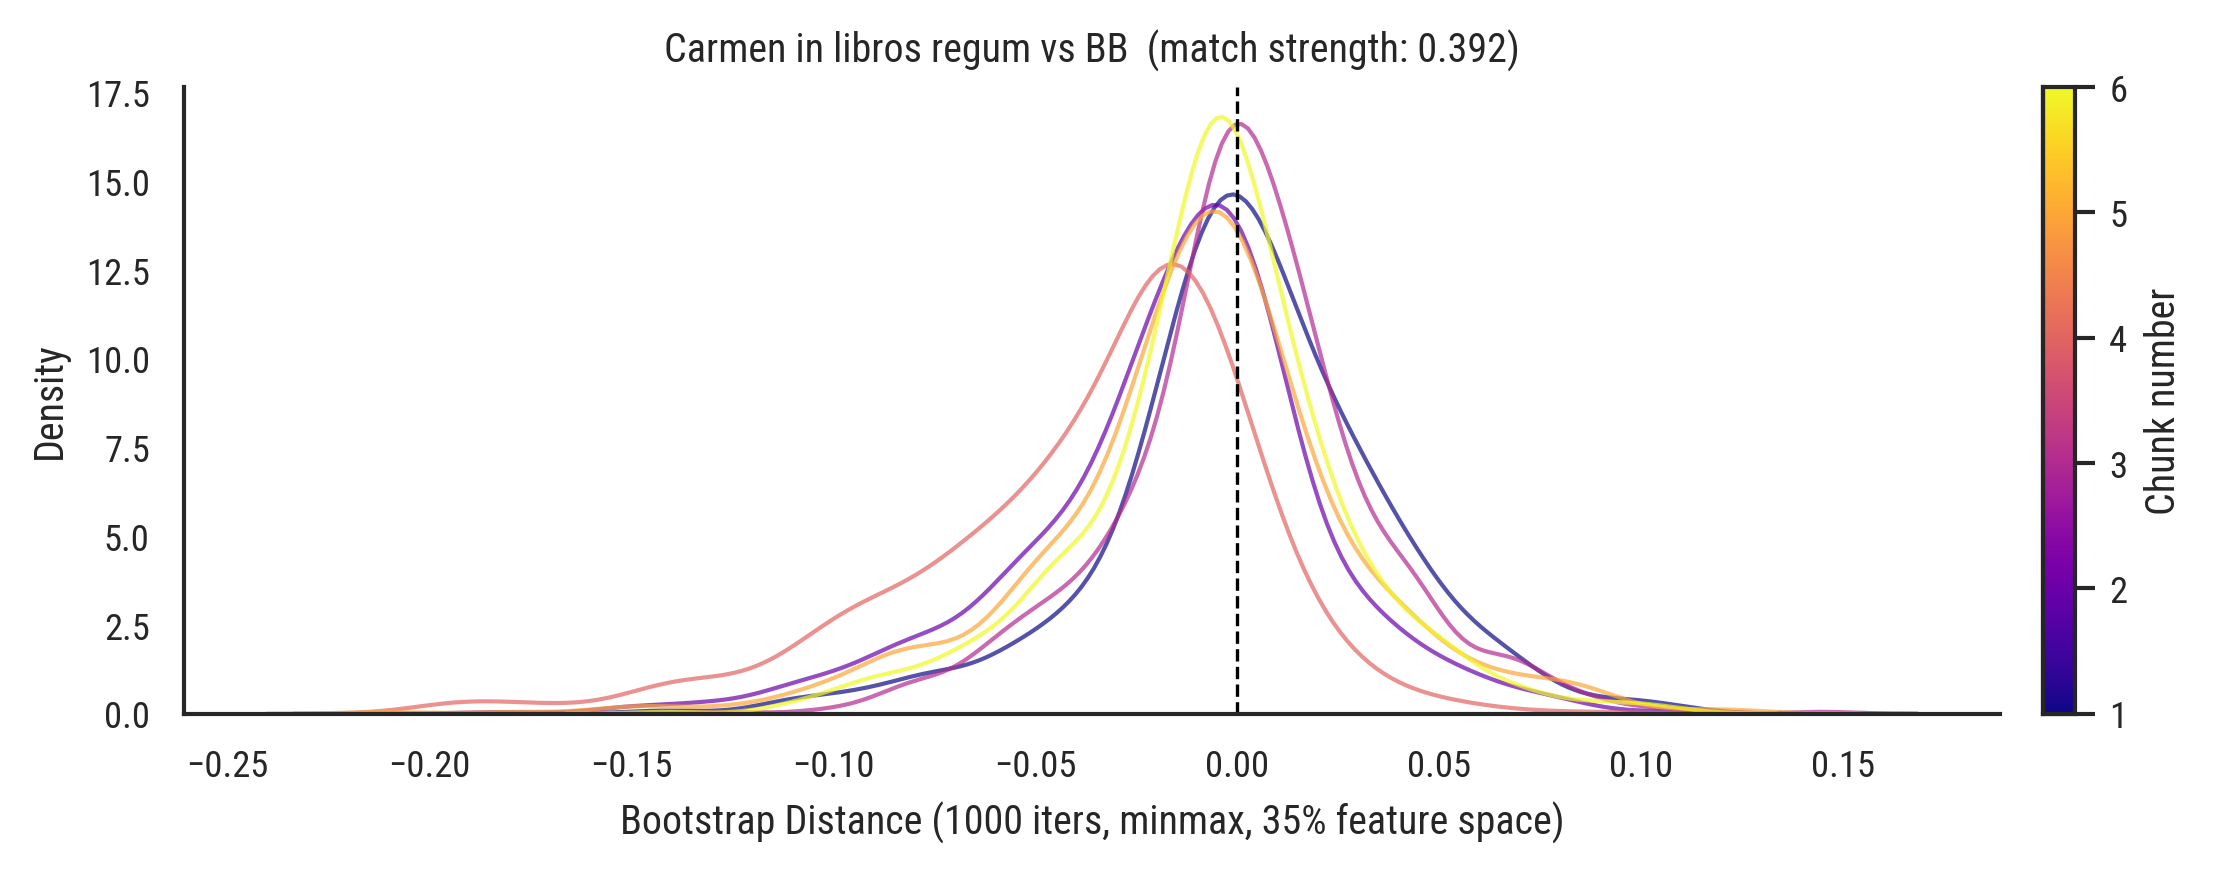

In [25]:
candidates = ["U4", "BB"]

sns.set_theme(
    context="paper",
    font="Roboto Condensed",
    style="white",
    rc={"figure.figsize": (8, 3), "figure.dpi": 300},
)

for candidate in candidates:
    label_idx = label_encoder.transform([candidate])[0]
    bdi_mm.predict_proba(
        problem_X,
        [label_idx] * problem_X.shape[0],
    )

    dist_df = pd.DataFrame(
        dict(zip(raw_df.loc[problem_mask].index, bdi_mm._dist_arrays))
    )

    mean_str = results[candidate]["mean"]
    fig, ax = plt.subplots(figsize=(8, 3))
    plot_kde_viridis(
        dist_df,
        poem_names,
        title=f"Carmen in libros regum vs {candidate}  (match strength: {mean_str:.3f})",
        xlabel="Bootstrap Distance (1000 iters, minmax, 35% feature space)",
        ax=ax,
    )
    sns.despine()
    fig.tight_layout()
    plt.savefig(f"carmen_in_libros_regum_vs_{candidate}.png", dpi=300, bbox_inches="tight")
    plt.show()